In [114]:
import pandas as pd
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import *

In [115]:
df = pd.read_csv("Admission_Predict - Admission_Predict.csv")

In [116]:
df=df.drop("Serial No.",axis=1)

In [117]:
df.head()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,337,118,4,4.5,4.5,9.65,1.0,0.92
1,324,107,4,4.0,4.5,8.87,1.0,0.76
2,316,104,3,3.0,3.5,8.00,1.0,0.72
3,322,110,3,3.5,2.5,8.67,1.0,0.80
4,314,103,2,2.0,3.0,8.21,0.0,0.65


In [118]:
df['admit'] = df['Chance of Admit'].apply(lambda x: 1 if x>0.85 else 0)

In [119]:
df.head()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,admit
0,337,118,4,4.5,4.5,9.65,1.0,0.92,1
1,324,107,4,4.0,4.5,8.87,1.0,0.76,0
2,316,104,3,3.0,3.5,8.00,1.0,0.72,0
3,322,110,3,3.5,2.5,8.67,1.0,0.80,0
4,314,103,2,2.0,3.0,8.21,0.0,0.65,0


In [120]:
df = df.drop('Chance of Admit',axis=1)

In [121]:
df.head()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,admit
0,337,118,4,4.5,4.5,9.65,1.0,1
1,324,107,4,4.0,4.5,8.87,1.0,0
2,316,104,3,3.0,3.5,8.00,1.0,0
3,322,110,3,3.5,2.5,8.67,1.0,0
4,314,103,2,2.0,3.0,8.21,0.0,0


In [122]:
df.isnull().sum()

GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             3
admit                0
dtype: int64

In [123]:
df["Research"] = pd.to_numeric(df["Research"],errors= "coerce")
df['Research'] = df['Research'].fillna(df['Research'].mode()[0])

In [124]:
df.isnull().sum()

GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
admit                0
dtype: int64

In [125]:
X = df.drop('admit',axis=1)
y = df['admit']

In [126]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [127]:
tree = DecisionTreeClassifier(criterion = 'entropy',max_depth = 3)
tree.fit(X_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [128]:
y_pred = tree.predict(X_test)

In [129]:
print("Confusion matrix for the tree:")
print(confusion_matrix(y_test,y_pred))

Confusion matrix for the tree:
[[58  1]
 [ 2 19]]


In [130]:
print("Accuracy Score:",accuracy_score(y_test,y_pred))
print("Precision",precision_score(y_test,y_pred))
print("Recall",recall_score(y_test,y_pred))

Accuracy Score: 0.9625
Precision 0.95
Recall 0.9047619047619048


[Text(0.5, 0.875, 'x[5] <= 9.185\nentropy = 0.709\nsamples = 320\nvalue = [258, 62]'),
 Text(0.25, 0.625, 'x[5] <= 8.93\nentropy = 0.293\nsamples = 271\nvalue = [257, 14]'),
 Text(0.375, 0.75, 'True  '),
 Text(0.125, 0.375, 'entropy = 0.0\nsamples = 225\nvalue = [225, 0]'),
 Text(0.375, 0.375, 'x[2] <= 4.5\nentropy = 0.887\nsamples = 46\nvalue = [32, 14]'),
 Text(0.25, 0.125, 'entropy = 0.689\nsamples = 38\nvalue = [31, 7]'),
 Text(0.5, 0.125, 'entropy = 0.544\nsamples = 8\nvalue = [1, 7]'),
 Text(0.75, 0.625, 'x[1] <= 109.5\nentropy = 0.144\nsamples = 49\nvalue = [1.0, 48.0]'),
 Text(0.625, 0.75, '  False'),
 Text(0.625, 0.375, 'entropy = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.875, 0.375, 'entropy = 0.0\nsamples = 48\nvalue = [0, 48]')]

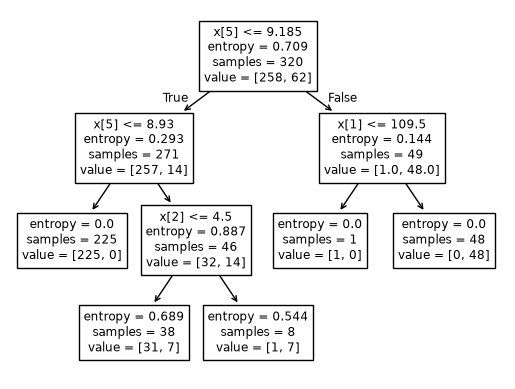

In [131]:
plot_tree(tree)

In [132]:
df.dtypes

GRE Score              int64
TOEFL Score            int64
University Rating      int64
SOP                  float64
LOR                  float64
CGPA                 float64
Research             float64
admit                  int64
dtype: object

In [133]:
nb = GaussianNB()
nb.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[258., 62.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.81,0.19]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.271e-07
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['GRE Score','TOEFL Score','University Rating',...,'LOR','CGPA','Research']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 7)","[[313.35,105.52, 2.71,..., 3.23, 8.39, 0.44], [331.39,115.44, 4.53,..., 4.38, 9.39, 0.95]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 7)","[[87.34,23.47, 0.89,..., 0.67, 0.22, 0.25], [30.27,10.15, 0.38,..., 0.27, 0.07, 0.05]]"


In [134]:
y_pred_nb = nb.predict(X_test)

In [135]:
print("\nConfusion matrix for Naive Bayes:")
print(confusion_matrix(y_test, y_pred_nb))

print("Accuracy Score:", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(y_test, y_pred_nb, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_nb, zero_division=0))


Confusion matrix for Naive Bayes:
[[57  2]
 [ 0 21]]
Accuracy Score: 0.975
Precision: 0.9130434782608695
Recall: 1.0


In [136]:
def get_admission():
    gre = int(input("Enter your GRE Score (Out of 340): "))
    toefl = int(input("Enter your TOEFL Score (Out of 120): "))
    uni = int(input("Enter your university ranking:"))
    sop = float(input("Enter SOP score (Out of 5): "))
    lor = float(input("Enter LOR score (Out of 5): "))
    cgpa = float(input("Enter your CGPA: "))
    research = float(input("Research? \n1: Yes\n2: No"))
    
    prediction = nb.predict([[gre,toefl,uni,sop,lor,cgpa,research]])
    if prediction == 1:
        print("The student will get admission.")
    else:
        print("The student will not get admission.")

In [137]:
get_admission()

Enter your GRE Score (Out of 340):  320
Enter your TOEFL Score (Out of 120):  110
Enter your university ranking: 7
Enter SOP score (Out of 5):  4.5
Enter LOR score (Out of 5):  4
Enter your CGPA:  9.20
Research? 
1: Yes
2: No 1


The student will get admission.


C:\Users\vishw\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(
